## We change the LR from 1e-3 to 1e-4

## Imports 

In [15]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src")))

In [16]:
import tensorflow as tf
import numpy as np
import os, glob
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from preprocessing import AudioPipeline
from preprocessing.dataset_pipeline import load_and_preprocess, make_dataset
from preprocessing.transfer_model import build_transfer_model
from sklearn.metrics import classification_report, confusion_matrix

## Config

In [17]:
DATA_DIR    = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/data/raw"
CLASSES     = ["talky", "silence", "unknown"]
BATCH_SIZE  = 16      
EPOCHS   = 50       # backbone gelé
LR       = 1e-4
KERAS_PATH  = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src/models/miniresnetv2_s1_64x50_tl.keras"

pipeline = AudioPipeline("/home/f24achba/Documents/Edge AI/52-Hertz-KWS/configuration/config.yaml")

## Chargement des chemins + labels 

In [18]:
all_paths, all_labels = [], []

for label_idx, class_name in enumerate(CLASSES):
    wavs = glob.glob(os.path.join(DATA_DIR, class_name, "*.wav"))
    all_paths  += wavs
    all_labels += [label_idx] * len(wavs)
    print(f"  {class_name:10s} → {len(wavs)} fichiers")

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f"\nTotal : {len(all_paths)} samples\n")

  talky      → 295 fichiers
  silence    → 135 fichiers
  unknown    → 326 fichiers

Total : 756 samples



## Split 

In [19]:
# train 70% / val 15% / test 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    all_paths, all_labels,
    test_size=0.30,
    stratify=all_labels,    
    random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}")


Train : 529 | Val : 113 | Test : 114


## Class weights 

In [20]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f"\nClass weights : {class_weight_dict}")


Class weights : {0: 0.8559870550161812, 1: 1.856140350877193, 2: 0.7733918128654971}


## tf.data pipeline 

In [21]:
train_ds = make_dataset(X_train, y_train, BATCH_SIZE, augment=True)
val_ds   = make_dataset(X_val,   y_val, BATCH_SIZE,  augment=False)
test_ds  = make_dataset(X_test,  y_test, BATCH_SIZE, augment=False)

## model 

In [22]:

model = build_transfer_model(KERAS_PATH, num_classes=3)
model.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "miniresnet_kws"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_4             │ (None, 64, 50, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 70, 56, 1) │          0 │ input_4[0][0]     │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 32, 25,    │      3,200 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 34, 27,    │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 16, 13,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 16, 13,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 16, 13,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 18, 15,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 16, 13,    │      4,160 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 16, 13,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 16, 13,    │          0 │ conv2_block1_0_c… │
│ (Add)               │ 64)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │        256 │ conv2_block1_out… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │          0 │ conv2_block2_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block2_pre

 Total params: 101,315 (395.76 KB)

 Trainable params: 10,755 (42.01 KB)

 Non-trainable params: 90,560 (353.75 KB)

## Callbacks 

In [23]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v1s2_modifiedLR.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,                  # généreux : courbes bruitées avec peu de data
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]


## Training

In [24]:
print("\n Feature extraction (backbone gelé)")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict   # compense le déséquilibre
)


 Feature extraction (backbone gelé)
Epoch 1/50
16/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3493 - loss: 1.0917
Epoch 1: val_accuracy improved from None to 0.57522, saving model to best_model_resnet_v1s2_modifiedLR.keras
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3459 - loss: 1.1012 - val_accuracy: 0.5752 - val_loss: 1.0935 - learning_rate: 1.0000e-04
Epoch 2/50
33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3511 - loss: 1.1074
Epoch 2: val_accuracy did not improve from 0.57522
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3611 - loss: 1.0996 - val_accuracy: 0.4602 - val_loss: 1.0911 - learning_rate: 1.0000e-04
Epoch 3/50
33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3652 - loss: 1.1001
Epoch 3: val_accuracy did not improve from 0.57522
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3459 - loss: 1.0976 - val_accuracy: 0.3097 - val_loss: 1.0966 - learning_rate: 1.0000e-04
Epoch 4/50
17/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3031

## Best model 

In [25]:
model = tf.keras.models.load_model("best_model_resnet_v1s2_modifiedLR.keras")  
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy : {acc:.3f}")

Test accuracy : 0.851


## Confusion matrix

In [26]:

y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)
print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
              precision    recall  f1-score   support

       talky       0.87      0.87      0.87        45
     silence       1.00      0.65      0.79        20
     unknown       0.80      0.92      0.86        49

    accuracy                           0.85       114
   macro avg       0.89      0.81      0.84       114
weighted avg       0.86      0.85      0.85       114



In [27]:
best_epoch = np.argmax(history.history["val_accuracy"]) + 1
best_val_acc = np.max(history.history["val_accuracy"])

print(f"Best Epoch : {best_epoch}")
print(f"Val Acc : {best_val_acc})")

Best Epoch : 40
Val Acc : 0.9469026327133179)


Plot the value accuracy in fct of the number of epoch

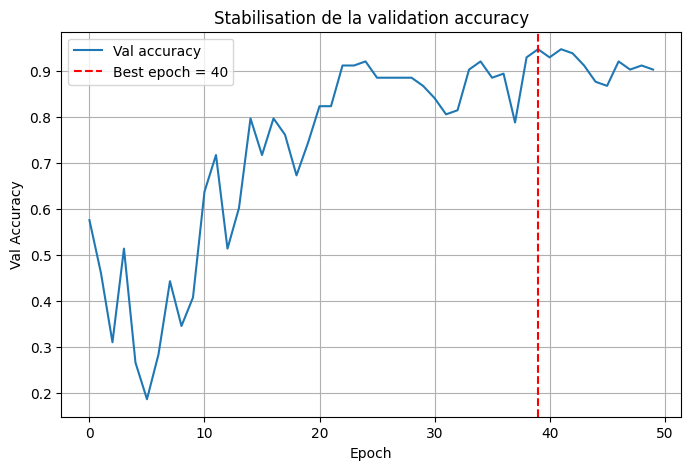

Best val acc: 0.9469026327133179


In [28]:
import numpy as np
import matplotlib.pyplot as plt

val_acc = history.history["val_accuracy"]
best_epoch = np.argmax(val_acc)

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Val accuracy")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch+1}")

plt.xlabel("Epoch")
plt.ylabel("Val Accuracy")
plt.title("Stabilisation de la validation accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("Best val acc:", val_acc[best_epoch])


### Plot the loss in fct of the number of epochs

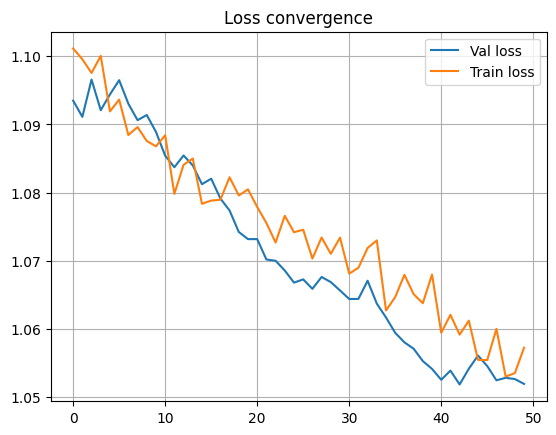

In [29]:
plt.plot(history.history["val_loss"], label="Val loss")
plt.plot(history.history["loss"], label="Train loss")
plt.legend()
plt.grid()
plt.title("Loss convergence")
plt.show()

Il n'y a pas de moment où la loss d'entraînement continue à baisser tandis que la loss de validation remonte fortement => pas d'overfitting